# Protección frente al despido y tasa de paro

In [ ]:
# Parámetros de la gráfica
SLUG = "economia"  # carpeta en research/temas/
GRAFICA_ID = "proteccion-empleo-paro"  # id de la gráfica (kebab-case) = nombre del notebook
TITULO = "Protección frente al despido y tasa de paro"  # `titulo` de la gráfica en config.json
DESDE = 1976  # primer año candidato (METODOLOGIA §2.3)
UNIVERSO = "ocde"  # ocde | ue27: todos sus países con dato en los dos ejes (METODOLOGIA §2.6)
EJE_X = {"titulo": "Rigidez de la protección frente al despido", "unidad": "índice de 0 (menor) a 6"}
EJE_Y = {"titulo": "Tasa de paro", "unidad": "% de la población activa"}
ANIOS = None  # (desde, hasta) si el config fija una ventana; None = último año común de cada país
CSV_FORMATO = "es"  # CSV: "es" (separador ; y coma decimal, Excel en español) o "int" (, y punto)
CSV_DECIMALES = 2  # decimales del CSV (el JSON guarda el valor completo)
DIR_SALIDA = None  # solo tests; None = temas/<SLUG>/data/

## 1. Contexto

Cada punto es un país de la OCDE con dato en los dos ejes.

- **Eje horizontal:** el indicador de la OCDE de **rigidez de la protección de los contratos indefinidos frente al despido**, individual y colectivo, de 0 (menor rigidez) a 6. Mide lo que establece la legislación (preaviso, indemnizaciones, causas de despido, procedimientos, recursos), no cómo se aplica.
- **Eje vertical:** la **tasa de paro**, el porcentaje de la población activa de 15 años o más que no tiene empleo y lo busca, en media anual y con la definición armonizada de la OCDE.

**Para qué sirve.** Pone junto a la protección frente al despido el resultado que invocan quienes proponen reducirla: que una protección alta desincentiva la contratación y mantiene el paro. Quienes proponen mantenerla o aumentarla sostienen que protege a quienes trabajan sin ser decisiva para el paro, que se atribuye a otros factores, y la gráfica permite las dos lecturas (la comparación con el crecimiento de las empresas está en `proteccion-empleo-empresas-alto-crecimiento`). **La relación entre dos indicadores no muestra que uno cause el otro**: no se dibuja línea de tendencia ni se calcula la correlación.

**Limitaciones.**
- El indicador solo recoge la protección de los contratos indefinidos; la de los temporales, la dualidad entre ambos y la forma en que se aplican las normas quedan fuera.
- El paro depende de muchos factores además de la regulación: el ciclo económico, la estructura productiva y las políticas activas de empleo.
- Cada punto usa el último año en que el país tiene dato en los dos ejes.

## 2. Descarga

- **OCDE, indicadores de legislación de protección del empleo** (`OECD.ELS.JAI,DSD_EPL@DF_EPL`, versión 1.0): `EPL_OV` (contratos indefinidos, despidos individuales y colectivos), metodología `VERSION4` (la más reciente, con España y 43 áreas desde 2013), escala de 0 a 6.
- **OCDE, Encuestas de población activa** (`OECD.SDD.TPS,DSD_LFS@DF_IALFS_UNE_M`, versión 1.0): tasa de paro (`UNE_LF_M`) de la población de 15 años o más, total, media anual, en % de la población activa.
- **Nota sobre el código:** se usa `EPL_OV`, que recoge el despido individual y el colectivo; `EPL_R` en este dataflow es solo el despido individual (decisión humana del 2026-10-22, `pending.md`).

In [ ]:
import sys
from pathlib import Path

# Raíz del proyecto (la carpeta con global.json y lib/), buscando hacia arriba desde el directorio de ejecución
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "global.json").exists()), None)
if RAIZ is None:
    raise FileNotFoundError(
        "No se encuentra global.json. Abre el notebook desde su carpeta (temas/<tema>/notebooks/) "
        "dentro del repositorio completo; consulta el README para instalar el entorno."
    )
sys.path.insert(0, str(RAIZ))

import pandas as pd

from lib import estilos
from lib.paises import paises_de
from lib.writer import construir_dispersion_data, write_dispersion_data

PAISES = paises_de(UNIVERSO)

from datetime import date

from lib import eurostat, oecd
from lib.paises import nombre_punto
from lib.tipos import FuenteMeta

AREAS = {c: c for c in PAISES}  # todos los países del universo, con su código como clave de serie
HOY = date.today().isoformat()

# Protección del empleo (OCDE, indicadores EPL): contratos indefinidos, despidos individuales y colectivos
DATAFLOW_EPL = "OECD.ELS.JAI,DSD_EPL@DF_EPL,1.0"
# Dimensiones: frecuencia . país . medida . unidad (escala de 0 a 6) . versión de la metodología
MEDIDA_EPL = "EPL_OV"  # contratos indefinidos, despidos individuales y colectivos (EPL_R: solo individuales)
VERSION_EPL = "VERSION4"  # la más reciente: cubre España y 43 áreas desde 2013
CLAVE_EPL = "A.{AREA}." + f"{MEDIDA_EPL}.0_TO_6.{VERSION_EPL}"
# Tasa de paro armonizada (OCDE, Encuestas de población activa): media anual, total, 15 años o más
DATAFLOW_UNE = "OECD.SDD.TPS,DSD_LFS@DF_IALFS_UNE_M,1.0"
# Dimensiones: país . medida . unidad . transformación . ajuste . sexo . edad . actividad . frecuencia
CLAVE_UNE = "{AREA}.UNE_LF_M.PT_LF_SUB._Z.N._T.Y_GE15._Z.A"

x, _ = oecd.get(DATAFLOW_EPL, CLAVE_EPL, areas=AREAS, desde=DESDE)
y, _ = oecd.get(DATAFLOW_UNE, CLAVE_UNE, areas=AREAS, desde=DESDE)
# Medias: la OCDE publica su agregado en las dos fuentes (el punto, solo si las dos lo publican)
media_x, _ = oecd.get(DATAFLOW_EPL, CLAVE_EPL, areas={"OECD": "OECD"}, desde=DESDE)
media_y, _ = oecd.get(DATAFLOW_UNE, CLAVE_UNE, areas={"OECD": "OECD"}, desde=DESDE)
print("Países con protección del empleo:", x["serie"].nunique(), "· con tasa de paro:", y["serie"].nunique())

Países con protección del empleo: 38 · con tasa de paro: 38


## 3. Transformación

1. Los dos ejes se usan tal como los publica la OCDE, sin transformar.
2. **Punto de la media OCDE:** las dos fuentes publican un agregado de la OCDE y se añade como punto (con su propio año). La UE-27 no se publica en el indicador de protección del empleo y no hay punto.
3. El escritor elige para cada país el último año con dato en los dos ejes, el mismo para `x` e `y`.

In [ ]:
def unir(xs):
    xs = [str(x) for x in xs]
    return xs[0] if len(xs) == 1 else f"{', '.join(xs[:-1])} y {xs[-1]}"


def es(v, d=1):
    return estilos.formato_es(v, d)


def notas_epl(x, v):
    """Notas comunes del eje de la protección frente al despido (OCDE, EPL)."""
    _, flujo, version = DATAFLOW_EPL.split(",")
    notas = [
        f"Protección del empleo: OCDE, indicadores de legislación de protección del empleo ({flujo}, versión {version}): "
        f"indicador {MEDIDA_EPL} (contratos indefinidos, despidos individuales y colectivos), escala de 0 (menor "
        f"rigidez) a 6, metodología {VERSION_EPL}. Mide lo que dice la ley, no cómo se aplica.",
    ]
    esp = x[x["serie"] == "ESP"].set_index("periodo")["valor"]
    if len(esp):
        cambios = esp[esp.diff().abs() > 1e-9].index.tolist()
        notas.append(
            f"La serie de España empieza en {int(esp.index.min())}, después de la reforma laboral de 2012, y la fuente "
            f"solo cambia su valor en {unir(cambios) if cambios else 'ningún año'}; la reforma de 2021 actuó sobre "
            "todo en la contratación temporal, que este indicador no recoge."
        )
    return notas


assert not media_x.empty and not media_y.empty, "Falta la media OCDE en uno de los ejes"
# La media OCDE como un punto más (código OECD): una sola serie en cada eje
x = pd.concat([x, media_x], ignore_index=True)
y = pd.concat([y, media_y], ignore_index=True)

_, FLUJO_EPL, VERSION_EPL_FLUJO = DATAFLOW_EPL.split(",")
_, FLUJO_UNE, VERSION_UNE = DATAFLOW_UNE.split(",")
fuentes = [
    FuenteMeta("eje_x", oecd.ORGANISMO, f"{FLUJO_EPL} (EPL, versión {VERSION_EPL_FLUJO}): {MEDIDA_EPL}, 0_TO_6, {VERSION_EPL}", oecd.URL_EXPLORER, HOY),
    FuenteMeta("eje_y", oecd.ORGANISMO, f"{FLUJO_UNE} (Encuestas de población activa, versión {VERSION_UNE}): UNE_LF_M, Y_GE15, _T, media anual", oecd.URL_EXPLORER, HOY),
]
NOTAS = notas_epl(x, VERSION_EPL) + [
    f"Tasa de paro: OCDE, Encuestas de población activa ({FLUJO_UNE}, versión {VERSION_UNE}): porcentaje de la población "
    "activa de 15 años o más, media anual, definición armonizada.",
    "Media OCDE: el indicador de protección es el que publica la OCDE para su agregado y la tasa de paro, el agregado "
    "de la OCDE, que no es una media simple de los países; cada punto usa su último año común.",
    "El paro depende del ciclo económico y de la estructura productiva, además de la regulación.",
]

## 4. Visualización

Un punto por país, sin línea de tendencia ni correlación (METODOLOGIA §2.6).

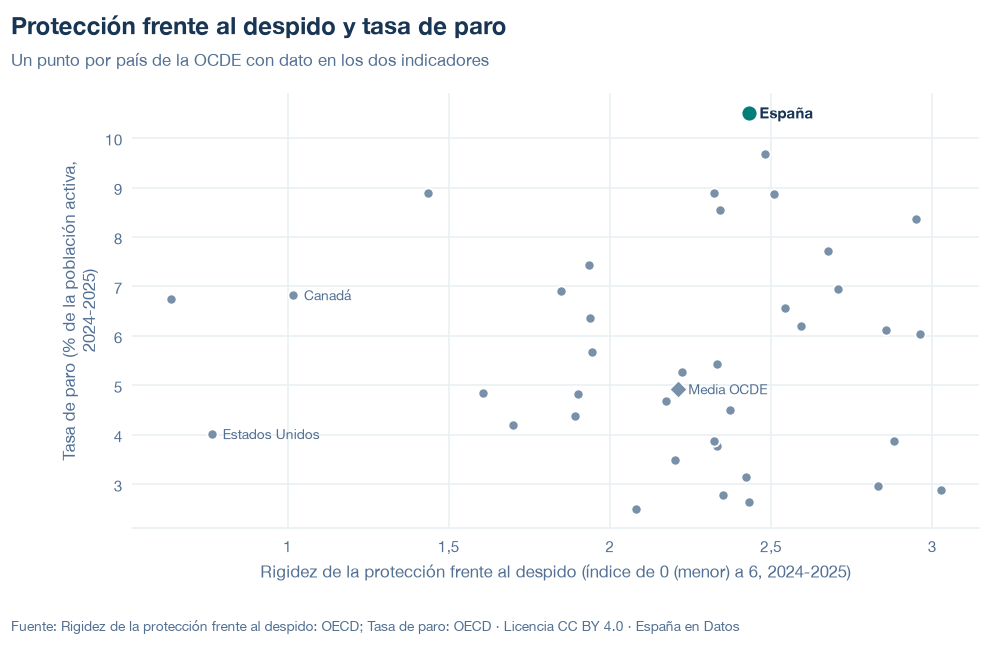

codigo  anio        x         y
   AUS  2025 1.700078  4.195469
   AUT  2025 1.943488  5.683333
   BEL  2025 2.591117  6.200000
   CAN  2025 1.017807  6.825000
   CHE  2025 1.606974  4.840408
   CHL  2025 2.341766  8.545018
   COL  2025 1.435811  8.897500
   CRI  2025 0.636905  6.739376
   CZE  2025 3.025262  2.891667
   DEU  2025 2.332411  3.766667
   DNK  2025 1.937693  6.358333
   ESP  2025 2.430514 10.516670
   EST  2025 1.934223  7.441667
   FIN  2025 2.479751  9.683333
   FRA  2025 2.675937  7.725000
   GBR  2025 1.901724  4.825000
   GRC  2025 2.321401  8.891666
   HUN  2025 1.892335  4.375000
   IRL  2025 2.173195  4.683333
   ISL  2024 2.203089  3.500000
   ISR  2024 2.832093  2.966667
   ITA  2025 2.855566  6.125000
   JPN  2025 2.080915  2.508333
   KOR  2025 2.350234  2.791667
   LTU  2025 1.848945  6.908333
   LUX  2025 2.541837  6.575000
   LVA  2025 2.708121  6.941667
   MEX  2025 2.430804  2.645921
   NLD  2025 2.880873  3.883333
   NOR  2025 2.373485  4.508333
   NZL  

In [ ]:
datos = construir_dispersion_data(
    x, y, fuentes, id=GRAFICA_ID, universo=UNIVERSO, eje_x=EJE_X, eje_y=EJE_Y, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, anios=ANIOS,
)
fig = estilos.figura(datos, titulo=TITULO)
estilos.mostrar(fig)
print(pd.DataFrame(datos["puntos"]).to_string(index=False))

## 5. Exportación

Escribe `data/<id>.json` (validado contra el esquema) y `data/<id>.csv`, el mismo CSV que se descarga en la web (`codigo;pais;anio;eje_x;eje_y`).

In [ ]:
salida = Path(DIR_SALIDA) if DIR_SALIDA else RAIZ / "temas" / SLUG / "data"
ruta = write_dispersion_data(
    x, y, fuentes, id=GRAFICA_ID, universo=UNIVERSO, eje_x=EJE_X, eje_y=EJE_Y, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, anios=ANIOS,
    path=salida / f"{GRAFICA_ID}.json", csv_formato=CSV_FORMATO, csv_decimales=CSV_DECIMALES,
)
print(f"escrito: data/{ruta.name} y data/{ruta.stem}.csv")  # sin rutas locales en las salidas publicadas

escrito: data/proteccion-empleo-paro.json y data/proteccion-empleo-paro.csv


## 6. Fuentes, notas y licencia

- OCDE, indicadores de protección del empleo: `OECD.ELS.JAI,DSD_EPL@DF_EPL,1.0` (`EPL_OV`, `0_TO_6`, `VERSION4`).
- OCDE, Encuestas de población activa: `OECD.SDD.TPS,DSD_LFS@DF_IALFS_UNE_M,1.0` (`UNE_LF_M`, `PT_LF_SUB`, `_T`, `Y_GE15`, frecuencia anual).

La fecha de consulta de cada eje está en `fuentes` del JSON; las notas incluyen los países sin dato y la advertencia de que la relación no muestra causa.

**Licencia:** datos, gráficos y textos CC BY 4.0; código MIT. Cita a España en Datos.